# STEP5. 산업별 금리베타 차이 검정 (Baseline)

## 분석 질문

STEP4에서 추정한 산업별 금리베타 차이가 표본의 우연이 아니라 통계적으로 유의한 차이인가?

- **관련 가설** — Baseline(산업 간 차이). $H_0:$ 7개 산업 금리베타가 모두 같다 / 대립: 적어도 한 산업은 다르다.
- **선행 단계** — STEP4(산업별 금리베타 추정)에서 산업별 개별 회귀로 베타를 구했다. 이번 단계는 같은 베타를 통합 회귀로 재현하고, 산업 간 차이를 통계적으로 검정한다.

## 입력

| 구분 | 경로 |
|---|---|
| 산업·KOSPI·금리 패널 | `data/processed/industry_rate_panel_daily.csv` |
| 구현 코드 | `src/models.py` (`industry_rate_betas`) |
| 이전 STEP 결과 | STEP4 — `beta_table`을 동일 함수로 재계산해 노트북 단독으로 재현한다. |

## 출력

**Table** — `results/Baseline_industry_beta/tables/` (4종)

| 파일 | 내용 |
|---|---|
| `industry_beta_from_pooled_model.csv` | 통합 회귀 산업별 베타 |
| `step4_vs_step5_beta_validation.csv` | STEP4-STEP5 베타 비교 |
| `industry_beta_joint_test.csv` | 공동검정 결과 |
| `industry_beta_pairwise_tests.csv` | 쌍별 비교 결과 |

**Figure** — `results/Baseline_industry_beta/figures/`

- `05_industry_beta_coefficient_plot.png`
- `05_pairwise_beta_difference_heatmap.png`

**Report**

- `results/Baseline_industry_beta/05_summary_final.html`

In [1]:
# 설정 · 데이터 로드



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from matplotlib import font_manager
from matplotlib.lines import Line2D

# 저장소 루트를 찾아 config를 불러온다 (실행 위치/편집기와 무관하게 동작).
# 저장소 루트에서 `pip install -e .` 를 한 번 실행했다면 아래 탐색은 건너뛴다.
import sys
from pathlib import Path

_anchors = []
if "__vsc_ipynb_file__" in globals():          # VS Code Notebook
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):                        # IPython 커널 시작 폴더 (Jupyter/Lab/Colab)
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())           # 최후 수단

# config.py 와 requirements.txt 를 '둘 다' 가진 폴더만 저장소 루트로 인정한다.
# 마커를 하나만 보면 다른 폴더의 동명 config.py 를 잘못 집을 수 있다.
_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
# 이미 sys.path에 있더라도 맨 앞으로 올린다. cwd(예: 바탕화면)가 앞에 있으면
# 같은 이름의 다른 config.py 가 먼저 잡히기 때문이다.
if _root is not None:
    if str(_root) in sys.path:
        sys.path.remove(str(_root))
    sys.path.insert(0, str(_root))

import config

if _root is not None and Path(config.__file__).resolve().parent != _root:
    raise ImportError(
        f"의도하지 않은 config.py 가 import 되었습니다: {config.__file__}\n"
        f"저장소 루트({_root})에서 `pip install -e .` 를 실행하세요."
    )

from src import models

# ---------------------------------------------------------------
# 한글 폰트 (OS별 후보를 순서대로 시도). 폰트가 없어도 분석은 진행한다.
# 특정 PC 경로(C:/Windows/...)만 보면 다른 팀원 환경에서 한글이 깨진다.
# ---------------------------------------------------------------
for _fp in ["C:/Windows/Fonts/malgun.ttf",
            "/Library/Fonts/AppleGothic.ttf",
            "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
            "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"]:
    if Path(_fp).exists():
        font_manager.fontManager.addfont(_fp)
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=_fp).get_name()
        break
else:
    for _name in ["Malgun Gothic", "AppleGothic", "NanumGothic",
                  "Noto Sans CJK KR", "Noto Sans CJK JP"]:
        if any(_name in f.name for f in font_manager.fontManager.ttflist):
            plt.rcParams["font.family"] = _name
            break
    else:
        print("한글 폰트를 찾지 못했습니다. 그래프의 한글이 깨질 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False
print("그래프 폰트:", plt.rcParams["font.family"])

BASELINE_DIR = config.BASELINE_DIR
TAB_DIR = BASELINE_DIR / "tables"
FIG_DIR = BASELINE_DIR / "figures"
TAB_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

panel = pd.read_csv(config.PROCESSED_DIR / "industry_rate_panel_daily.csv", encoding="utf-8-sig")
panel["date"] = pd.to_datetime(panel["date"])

beta_table = models.industry_rate_betas(panel)

print("panel:", panel.shape, "| 산업 수:", panel["industry"].nunique())

그래프 폰트: ['Noto Sans CJK JP']
panel: (17164, 12) | 산업 수: 7


## 분석 데이터 확인

### 왜 확인이 필요한가?

통합 회귀는 7개 산업을 하나의 회귀식 안에서 동시에 비교한다.
따라서 회귀를 돌리기 전에 산업 이름이 정확히 있는지, 필요한 변수(`industry_return`, `kospi_return`, `d_y3`)가 모두 있는지, 결측치로 산업별 표본 수가 달라지지 않는지를 확인한다.

In [2]:
# 분석 데이터 확인 및 정리
required_cols = ["date", "industry", "industry_return", "kospi_return", "d_y3"]
missing_cols = [col for col in required_cols if col not in panel.columns]

if missing_cols:
    raise ValueError(
        "panel에 STEP5 분석에 필요한 컬럼이 없습니다: " + ", ".join(missing_cols)
    )

h1_data = (
    panel[required_cols]
    .copy()
    .dropna()
    .sort_values(["date", "industry"])
    .reset_index(drop=True)
)

industries = sorted(h1_data["industry"].unique())
REFERENCE_INDUSTRY = "건설업" if "건설업" in industries else industries[0]

sample_check = (
    h1_data.groupby("industry")
    .agg(시작일=("date", "min"), 종료일=("date", "max"), 표본수=("date", "size"))
)

print("분석 행 수:", len(h1_data))
print("분석 산업 수:", len(industries))
print("산업 목록:", industries)
print("비교 설명에 사용할 기준 산업:", REFERENCE_INDUSTRY)
print("산업별 표본 수 동일 여부:", sample_check["표본수"].nunique() == 1)
display(sample_check)

분석 행 수: 17157
분석 산업 수: 7
산업 목록: ['건설업', '금융업', '운수장비', '의약품', '전기전자', '철강금속', '화학']
비교 설명에 사용할 기준 산업: 건설업
산업별 표본 수 동일 여부: True


,시작일,종료일,표본수
industry,,,
건설업,2016-01-05,2025-12-30,2451
금융업,2016-01-05,2025-12-30,2451
운수장비,2016-01-05,2025-12-30,2451
의약품,2016-01-05,2025-12-30,2451
전기전자,2016-01-05,2025-12-30,2451
철강금속,2016-01-05,2025-12-30,2451
화학,2016-01-05,2025-12-30,2451


### 관찰 결과

- 분석 행 수 **17,157건**, 분석 산업 수 **7개**(건설업·금융업·운수장비·의약품·전기전자·철강금속·화학).
- 산업별 표본 기간은 2016-01-05 ~ 2025-12-30로 **동일**하고, 표본 수도 산업별로 모두 **2,451건**으로 같다.

## 통합 회귀모형

산업별 회귀를 따로 돌리지 않고 7개 산업을 하나의 통합 회귀식에 넣어 동일 조건에서 비교한다.

$$
R_{i,t} = \sum_i D_i\left(\alpha_i + \beta^M_i R_{m,t}\right) + \sum_i D_i\,\delta_i\,\Delta y_{3Y,t} + \varepsilon_{i,t}
$$

`industry_return ~ 0 + C(industry) + C(industry):kospi_return + C(industry):d_y3`

$D_i$는 산업 더미, $\alpha_i$는 산업별 절편(`0 + C(industry)`), $\beta^M_i$는 산업별 시장베타(`C(industry):kospi_return`), $\delta_i$는 산업별 금리베타(`C(industry):d_y3`)다.

### 왜 표준오차를 두 가지로 계산하나?

표준오차는 STEP4와 동일하게 HAC(Newey-West)를 우선 적용한다.
다만 통합회귀는 같은 날짜에 7개 산업이 한 식에 동시에 들어가므로, 시계열 자기상관만 보정하는 HAC는 같은 날 여러 산업이 함께 받는 충격(횡단면 잔차 상관)을 반영하지 못한다.
이에 날짜를 클러스터 단위로 하는 Cluster-Robust 표준오차를 나란히 추가한다. HAC는 비교용으로 그대로 병기하고, 본문 결론의 판단 기준은 클러스터 표준오차로 삼는다.

In [3]:
# 통합 회귀모형 추정
HAC_LAGS = 5

h1_formula = (
    "industry_return ~ 0 + C(industry)"
    " + C(industry):kospi_return"
    " + C(industry):d_y3"
)

h1_model = smf.ols(
    formula=h1_formula,
    data=h1_data,
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": HAC_LAGS},
)

print("HAC maxlags:", HAC_LAGS)
print("관측치 수:", int(h1_model.nobs))
print("설명변수 수:", len(h1_model.params))

# 날짜 기준 Cluster Robust — 같은 날 7개 산업의 잔차 상관(횡단면 상관)을 보정한다.
# 통합회귀는 여러 산업을 한 식에 넣으므로 시계열 HAC만으로는 이 상관을 놓친다.
# 점추정(params)은 cov_type과 무관하므로 계수는 두 모형이 동일하다. SE·t·p·CI만 달라진다.
date_codes = pd.factorize(h1_data["date"])[0]

h1_model_cluster = smf.ols(formula=h1_formula, data=h1_data).fit(
    cov_type="cluster", cov_kwds={"groups": date_codes},
)

assert np.allclose(h1_model.params.values, h1_model_cluster.params.values), \
    "두 모형의 점추정이 다릅니다. 같은 식·같은 표본인지 확인하세요."

print("날짜 그룹 수:", len(np.unique(date_codes)))
print("점추정 일치 확인 — 최대 절대차:",
      float(np.max(np.abs(h1_model.params.values - h1_model_cluster.params.values))))

HAC maxlags: 5
관측치 수: 17157
설명변수 수: 21
날짜 그룹 수: 2451
점추정 일치 확인 — 최대 절대차: 0.0


### 관찰 결과

- 통합 회귀 관측치 수 **17,157건**, 설명변수 수 **21개**(산업별 절편 7 + 시장베타 7 + 금리베타 7).

## 통합 회귀에서 산업별 금리베타 추출

통합 회귀식에 산업별로 들어 있는 `d_y3` 상호작용 계수($\delta_i$)를 꺼내 표로 정리한다.
이 단계에서는 차이의 유의성을 판단하지 않고, 통합 회귀가 산업별 베타를 정상적으로 계산했는지만 확인한다.

In [4]:
# 통합 회귀에서 산업별 금리베타 추출
def find_rate_beta_param(model, industry):
    exact_name = f"C(industry)[{industry}]:d_y3"
    if exact_name in model.params.index:
        return exact_name

    candidates = [
        name for name in model.params.index
        if "C(industry)" in name
        and "d_y3" in name
        and str(industry) in name
    ]

    if len(candidates) != 1:
        raise KeyError(
            f"{industry}의 금리베타 계수명을 찾지 못했습니다. "
            f"후보: {candidates}"
        )
    return candidates[0]


beta_rows = []
h1_model_conf_int = h1_model.conf_int()
h1_model_cluster_conf_int = h1_model_cluster.conf_int()

for industry in industries:
    param_name = find_rate_beta_param(h1_model, industry)
    ci_low, ci_high = h1_model_conf_int.loc[param_name]

    beta_rows.append({
        "industry": industry,
        "beta_rate_pooled": h1_model.params[param_name],
        "std_error_pooled": h1_model.bse[param_name],
        "t_value_pooled": h1_model.tvalues[param_name],
        "p_value_pooled": h1_model.pvalues[param_name],
        "ci_lower_pooled": ci_low,
        "ci_upper_pooled": ci_high,
        "std_error_cluster": h1_model_cluster.bse[param_name],
        "t_value_cluster": h1_model_cluster.tvalues[param_name],
        "p_value_cluster": h1_model_cluster.pvalues[param_name],
        "ci_lower_cluster": h1_model_cluster_conf_int.loc[param_name][0],
        "ci_upper_cluster": h1_model_cluster_conf_int.loc[param_name][1],
        "parameter_name": param_name,
    })

pooled_beta_table = pd.DataFrame(beta_rows)

display(
    pooled_beta_table[
        [
            "industry",
            "beta_rate_pooled",
            "std_error_pooled",
            "t_value_pooled",
            "p_value_pooled",
            "ci_lower_pooled",
            "ci_upper_pooled",
            "std_error_cluster",
            "p_value_cluster",
        ]
    ].round(5)
)

,industry,beta_rate_pooled,std_error_pooled,t_value_pooled,p_value_pooled,ci_lower_pooled,ci_upper_pooled,std_error_cluster,p_value_cluster
0,건설업,0.00320,0.00728,0.44017,0.65982,-0.01107,0.01747,0.00729,0.66007
1,금융업,0.01123,0.00427,2.62983,0.00854,0.00286,0.01961,0.00427,0.00859
2,운수장비,0.01723,0.00580,2.96825,0.00299,0.00585,0.02861,0.00581,0.00302
3,의약품,-0.02707,0.00759,-3.56452,0.00036,-0.04195,-0.01218,0.00760,0.00037
4,전기전자,0.00159,0.00423,0.37513,0.70757,-0.00670,0.00988,0.00423,0.70779
5,철강금속,0.01884,0.00751,2.50925,0.01210,0.00412,0.03355,0.00751,0.01217
6,화학,0.00256,0.00477,0.53631,0.59174,-0.00679,0.01191,0.00477,0.59204


### 관찰 결과

- 통합 회귀에서 복원한 beta_rate_pooled는 의약품 <span style="color:#c0392b">**−0.02707**</span>(음)이 최대 절대값, 철강금속 <span style="color:#1f6feb">**+0.01884**</span>·운수장비 <span style="color:#1f6feb">**+0.01723**</span>·금융업 <span style="color:#1f6feb">**+0.01123**</span>이 유의한 양의 값으로 나타났다.
- 건설업(<span style="color:#9aa0a6">+0.00320</span>)·전기전자(<span style="color:#9aa0a6">+0.00159</span>)·화학(<span style="color:#9aa0a6">+0.00256</span>)은 p_value_pooled가 각각 0.65982·0.70757·0.59174로 크다.

## STEP4 개별회귀와의 재현 비교

STEP5의 통합 회귀는 산업별 절편·시장베타·금리베타를 모두 허용하므로, 산업별 금리베타 $\delta_i$ 자체는 STEP4의 개별 회귀 결과와 수학적으로 같아야 한다.
두 결과의 최대 절대 차이를 계산해 통합 모형이 올바르게 구성되었는지 확인한다.

In [5]:
# STEP4 개별회귀 베타와 STEP5 통합회귀 베타 비교
step4_compare = beta_table[
    ["industry", "beta_rate"]
].rename(
    columns={"beta_rate": "beta_rate_step4"}
)

beta_validation = (
    step4_compare
    .merge(
        pooled_beta_table[["industry", "beta_rate_pooled"]],
        on="industry",
        how="inner",
    )
)

beta_validation["difference"] = (
    beta_validation["beta_rate_pooled"]
    - beta_validation["beta_rate_step4"]
)

max_abs_diff = beta_validation["difference"].abs().max()
print("두 방식의 베타 최대 절대 차이:", max_abs_diff)
display(beta_validation.round(10))

두 방식의 베타 최대 절대 차이: 9.54097911787244e-16


,industry,beta_rate_step4,beta_rate_pooled,difference
0,건설업,0.003205,0.003205,-0.0
1,금융업,0.011234,0.011234,0.0
2,운수장비,0.017229,0.017229,0.0
3,의약품,-0.027066,-0.027066,0.0
4,전기전자,0.001587,0.001587,0.0
5,철강금속,0.018836,0.018836,0.0
6,화학,0.002558,0.002558,-0.0


### 관찰 결과

- STEP4와 STEP5 산업별 베타 최대 절대 차이 = **9.54e-16 (사실상 0)**.

## 산업별 금리베타 동일성 공동검정

산업별 베타 숫자가 다르다는 사실만으로는 표본의 우연한 흔들림인지 알 수 없다.
기준 산업과 나머지 산업의 베타 차이가 모두 0인지 Wald/F 검정으로 동시에 확인한다.

$$
H_0:\ \delta_1 = \delta_2 = \cdots = \delta_7
$$

대립가설은 적어도 한 산업의 금리베타가 다르다는 것이다.

In [6]:
# 산업별 금리베타 동일성 공동검정 (Wald/F 검정)
param_names = list(h1_model.params.index)
reference_param = find_rate_beta_param(h1_model, REFERENCE_INDUSTRY)

R = []

for industry in industries:
    if industry == REFERENCE_INDUSTRY:
        continue

    industry_param = find_rate_beta_param(h1_model, industry)
    restriction = np.zeros(len(param_names))

    restriction[param_names.index(industry_param)] = 1
    restriction[param_names.index(reference_param)] = -1
    R.append(restriction)

R = np.vstack(R)

try:
    joint_test = h1_model.wald_test(R, use_f=True, scalar=True)
except TypeError:
    joint_test = h1_model.wald_test(R, use_f=True)

joint_stat = float(np.asarray(joint_test.statistic).squeeze())
joint_pvalue = float(np.asarray(joint_test.pvalue).squeeze())

# 날짜 클러스터 표준오차 기준 공동검정 — 같은 제약행렬 R로 h1_model_cluster에 대해 검정
try:
    joint_test_cluster = h1_model_cluster.wald_test(R, use_f=True, scalar=True)
except TypeError:
    joint_test_cluster = h1_model_cluster.wald_test(R, use_f=True)

joint_stat_cluster = float(np.asarray(joint_test_cluster.statistic).squeeze())
joint_pvalue_cluster = float(np.asarray(joint_test_cluster.pvalue).squeeze())

joint_result = pd.DataFrame([{
    "test": "산업별 금리베타 동일성 공동검정",
    "reference_industry": REFERENCE_INDUSTRY,
    "statistic": joint_stat,
    "df_num": getattr(joint_test, "df_num", len(industries) - 1),
    "df_denom": getattr(joint_test, "df_denom", h1_model.df_resid),
    "p_value": joint_pvalue,
    "decision_5pct": (
        "H0 기각: 산업별 금리베타 차이 존재"
        if joint_pvalue < 0.05
        else "H0 기각 못함: 산업별 차이 근거 부족"
    ),
    "statistic_cluster": joint_stat_cluster,
    "p_value_cluster": joint_pvalue_cluster,
    "decision_5pct_cluster": (
        "H0 기각: 산업별 금리베타 차이 존재"
        if joint_pvalue_cluster < 0.05
        else "H0 기각 못함: 산업별 차이 근거 부족"
    ),
}])

display(joint_result.round(6))

print("공동검정 — HAC 기준: F =", round(joint_stat, 4), ", p =", round(joint_pvalue, 6))
print("공동검정 — 클러스터 기준: F =", round(joint_stat_cluster, 4), ", p =", round(joint_pvalue_cluster, 6))


,test,reference_industry,statistic,df_num,df_denom,p_value,decision_5pct,statistic_cluster,p_value_cluster,decision_5pct_cluster
0,산업별 금리베타 동일성 공동검정,건설업,4.26942,6.0,17136.0,0.000264,H0 기각: 산업별 금리베타 차이 존재,4.189156,0.000338,H0 기각: 산업별 금리베타 차이 존재


공동검정 — HAC 기준: F = 4.2694 , p = 0.000264
공동검정 — 클러스터 기준: F = 4.1892 , p = 0.000338


### 관찰 결과

- 공동검정 통계량 **4.26942**, p-value **0.000264**(자유도 6, 17136) — HAC 표준오차 기준.
- 날짜 클러스터 표준오차 기준으로는 통계량 **4.18916**, p-value **0.000338**(자유도 6, 17136)로 나타났다.
- 5% 유의수준에서 두 방식 모두 H0(7개 산업 금리베타 동일) **기각**하며, 결론은 동일하다.


## 산업 쌍별 금리베타 차이 검정

공동검정이 유의해도 어느 산업끼리 다른지는 알 수 없다.
7개 산업의 모든 쌍(21개)에 대해 다음 대비를 검정한다.

$$
H_0:\ \delta_a - \delta_b = 0 \quad (a \neq b)
$$

### 왜 BH 보정을 같이 하나?

비교가 21번 반복되면 우연히 유의한 결과가 나올 가능성이 커진다.
따라서 원래 p-value와 함께 BH(FDR) 보정 p-value도 함께 계산해 다중검정 문제를 통제한다.

In [7]:
# 산업 쌍별 금리베타 차이 검정과 BH 보정
pairwise_rows = []

for industry_a, industry_b in combinations(industries, 2):
    param_a = find_rate_beta_param(h1_model, industry_a)
    param_b = find_rate_beta_param(h1_model, industry_b)

    contrast = np.zeros(len(param_names))
    contrast[param_names.index(param_a)] = 1
    contrast[param_names.index(param_b)] = -1

    test = h1_model.t_test(contrast)
    test_cluster = h1_model_cluster.t_test(contrast)

    difference = float(np.asarray(test.effect).squeeze())
    std_error = float(np.asarray(test.sd).squeeze())
    t_value = float(np.asarray(test.tvalue).squeeze())
    p_value = float(np.asarray(test.pvalue).squeeze())
    ci_low, ci_high = np.asarray(test.conf_int()).reshape(-1, 2)[0]

    std_error_cluster = float(np.asarray(test_cluster.sd).squeeze())
    t_value_cluster = float(np.asarray(test_cluster.tvalue).squeeze())
    p_value_cluster = float(np.asarray(test_cluster.pvalue).squeeze())

    pairwise_rows.append({
        "industry_a": industry_a,
        "industry_b": industry_b,
        "beta_difference_a_minus_b": difference,
        "std_error": std_error,
        "t_value": t_value,
        "p_value": p_value,
        "ci_lower": ci_low,
        "ci_upper": ci_high,
        "std_error_cluster": std_error_cluster,
        "t_value_cluster": t_value_cluster,
        "p_value_cluster": p_value_cluster,
    })

pairwise_table = pd.DataFrame(pairwise_rows)

pairwise_table["p_value_bh"] = multipletests(
    pairwise_table["p_value"],
    method="fdr_bh",
)[1]

pairwise_table["significant_bh_5pct"] = (
    pairwise_table["p_value_bh"] < 0.05
)

pairwise_table["p_value_bh_cluster"] = multipletests(
    pairwise_table["p_value_cluster"], method="fdr_bh")[1]
pairwise_table["significant_bh_5pct_cluster"] = pairwise_table["p_value_bh_cluster"] < 0.05

pairwise_table = pairwise_table.sort_values(
    ["p_value_bh", "p_value"]
).reset_index(drop=True)

display(pairwise_table.round(5))

print(
    "BH 보정 후 유의한 산업 쌍 수:",
    int(pairwise_table["significant_bh_5pct"].sum()),
    "/",
    len(pairwise_table),
)

print("BH 보정 후 유의한 산업 쌍 — HAC 기준:",
      int(pairwise_table["significant_bh_5pct"].sum()), "/", len(pairwise_table))
print("BH 보정 후 유의한 산업 쌍 — 클러스터 기준:",
      int(pairwise_table["significant_bh_5pct_cluster"].sum()), "/", len(pairwise_table))
_flip = pairwise_table[
    pairwise_table["significant_bh_5pct"] != pairwise_table["significant_bh_5pct_cluster"]]
print("판정이 달라진 쌍:", len(_flip))
if len(_flip):
    display(_flip[["industry_a", "industry_b", "p_value_bh", "p_value_bh_cluster"]].round(5))

,industry_a,industry_b,beta_difference_a_minus_b,std_error,t_value,p_value,ci_lower,ci_upper,std_error_cluster,t_value_cluster,p_value_cluster,p_value_bh,significant_bh_5pct,p_value_bh_cluster,significant_bh_5pct_cluster
0,운수장비,의약품,0.04430,0.01009,4.39158,0.00001,0.02453,0.06406,0.01020,4.34400,0.00001,0.00018,True,0.00025,True
1,금융업,의약품,0.03830,0.00890,4.30263,0.00002,0.02085,0.05575,0.00906,4.22587,0.00002,0.00018,True,0.00025,True
2,의약품,철강금속,-0.04590,0.01122,-4.09234,0.00004,-0.06789,-0.02392,0.01149,-3.99637,0.00006,0.00030,True,0.00045,True
3,의약품,화학,-0.02962,0.00913,-3.24327,0.00118,-0.04753,-0.01172,0.00928,-3.19077,0.00142,0.00620,True,0.00745,True
4,의약품,전기전자,-0.02865,0.00922,-3.10855,0.00188,-0.04672,-0.01059,0.00933,-3.07227,0.00212,0.00790,True,0.00892,True
5,건설업,의약품,0.03027,0.01065,2.84160,0.00449,0.00939,0.05115,0.01082,2.79835,0.00514,0.01571,True,0.01798,True
6,철강금속,화학,0.01628,0.00765,2.12761,0.03337,0.00128,0.03127,0.00738,2.20484,0.02747,0.10011,False,0.08061,False
7,운수장비,화학,0.01467,0.00717,2.04554,0.04080,0.00061,0.02873,0.00679,2.16084,0.03071,0.10711,False,0.08061,False
8,운수장비,전기전자,0.01564,0.00822,1.90347,0.05698,-0.00046,0.03175,0.00869,1.80098,0.07171,0.13295,False,0.15006,False
9,전기전자,철강금속,-0.01725,0.00961,-1.79447,0.07274,-0.03609,0.00159,0.00981,-1.75884,0.07860,0.15275,False,0.15006,False


BH 보정 후 유의한 산업 쌍 수: 6 / 21
BH 보정 후 유의한 산업 쌍 — HAC 기준: 6 / 21
BH 보정 후 유의한 산업 쌍 — 클러스터 기준: 6 / 21
판정이 달라진 쌍: 0


### 관찰 결과

- BH 보정 후 5% 수준에서 유의한 산업 쌍은 **6개 / 21개**다.
- 유의한 6개 쌍은 모두 의약품을 포함하거나(운수장비-의약품, 금융업-의약품, 의약품-철강금속, 의약품-화학, 의약품-전기전자, 건설업-의약품) **의약품이 관여한 쌍**이다.
- 날짜 클러스터 기준으로 다시 계산해도 BH 유의 쌍은 동일하게 **6개 / 21개**이며, HAC 기준과 판정이 달라진 쌍은 **0개**다. **두 기준의 결론이 일치하므로 이 결과는 표준오차 선택에 견고하다.**

## 결과표 저장

통합 회귀 기반 산업별 베타, STEP4-STEP5 베타 비교표, 공동검정 결과, 쌍별 비교 결과를 CSV로 저장해 재사용할 수 있게 한다.

In [ ]:
# 결과표 저장
pooled_beta_table.to_csv(
    TAB_DIR / "industry_beta_from_pooled_model.csv",
    index=False,
    encoding="utf-8-sig",
)

beta_validation.to_csv(
    TAB_DIR / "step4_vs_step5_beta_validation.csv",
    index=False,
    encoding="utf-8-sig",
)

joint_result.to_csv(
    TAB_DIR / "industry_beta_joint_test.csv",
    index=False,
    encoding="utf-8-sig",
)

pairwise_table.to_csv(
    TAB_DIR / "industry_beta_pairwise_tests.csv",
    index=False,
    encoding="utf-8-sig",
)

# 개인 PC/실행환경 절대경로를 출력에 남기지 않는다 (config._rel: 저장소 루트 기준 상대경로).
print("저장 폴더:", config._rel(TAB_DIR))
for saved_file in sorted(TAB_DIR.glob("*.csv")):
    print(" -", saved_file.name)

## 산업별 금리베타 계수 플롯

산업별 금리베타($\beta_{rate,pooled}$)와 95% 신뢰구간을 계수 플롯으로 나타내 방향·크기·유의성을 한눈에 비교한다.

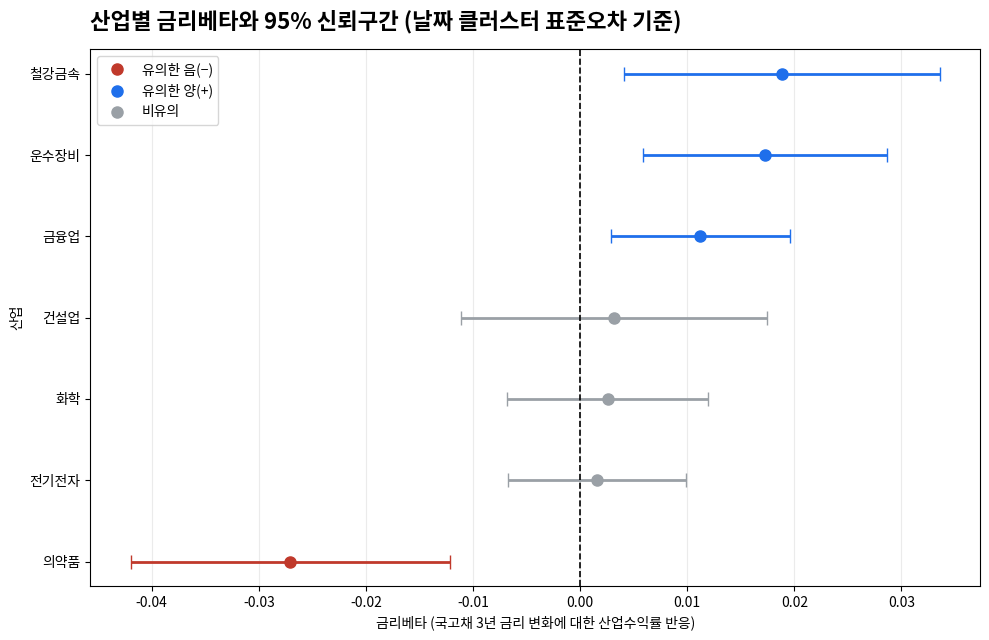

In [9]:
# 산업별 금리베타 계수 플롯
required_plot_cols = [
    "industry",
    "beta_rate_pooled",
    "ci_lower_cluster",
    "ci_upper_cluster",
    "p_value_cluster",
]

missing_plot_cols = [
    col for col in required_plot_cols
    if col not in pooled_beta_table.columns
]

if missing_plot_cols:
    raise ValueError(
        "시각화에 필요한 컬럼이 없습니다: " + ", ".join(missing_plot_cols)
    )

plot_beta = pooled_beta_table[required_plot_cols].copy()

numeric_cols = ["beta_rate_pooled", "ci_lower_cluster", "ci_upper_cluster", "p_value_cluster"]
for col in numeric_cols:
    plot_beta[col] = pd.to_numeric(plot_beta[col], errors="coerce")

plot_beta = plot_beta.replace([np.inf, -np.inf], np.nan)

invalid_rows = plot_beta[numeric_cols].isna().any(axis=1)
if invalid_rows.any():
    display(plot_beta.loc[invalid_rows])

plot_beta = (
    plot_beta.loc[~invalid_rows]
    .sort_values("beta_rate_pooled")
    .reset_index(drop=True)
)

if plot_beta.empty:
    raise ValueError(
        "시각화할 수 있는 산업별 베타 값이 없습니다. "
        "STEP5-2와 STEP5-3 회귀 결과를 먼저 확인하세요."
    )

lower_error = plot_beta["beta_rate_pooled"] - plot_beta["ci_lower_cluster"]
upper_error = plot_beta["ci_upper_cluster"] - plot_beta["beta_rate_pooled"]

if (lower_error < 0).any() or (upper_error < 0).any():
    raise ValueError(
        "신뢰구간의 하한·상한 순서가 올바르지 않습니다."
    )

# 프로젝트 색상 규칙(docs/STYLE_GUIDE.md §12): 음(-) 빨강 / 양(+) 파랑 / 비유의 회색.
NEG_COLOR = "#c0392b"
POS_COLOR = "#1f6feb"
NS_COLOR = "#9aa0a6"


def industry_beta_color(beta, p_value_cluster):
    if p_value_cluster < 0.05:
        return NEG_COLOR if beta < 0 else POS_COLOR
    return NS_COLOR


point_colors = [
    industry_beta_color(beta, p_value)
    for beta, p_value in zip(plot_beta["beta_rate_pooled"], plot_beta["p_value_cluster"])
]

y_positions = np.arange(len(plot_beta))

fig, ax = plt.subplots(figsize=(10, 6.5))

for y, beta, lo, hi, color in zip(
    y_positions,
    plot_beta["beta_rate_pooled"],
    lower_error,
    upper_error,
    point_colors,
):
    ax.errorbar(
        beta,
        y,
        xerr=[[lo], [hi]],
        fmt="o",
        markersize=8,
        capsize=5,
        elinewidth=2,
        color=color,
        ecolor=color,
    )

ax.axvline(x=0, linestyle="--", linewidth=1.2, color="black")
ax.set_yticks(y_positions)
ax.set_yticklabels(plot_beta["industry"])
ax.set_xlabel("금리베타 (국고채 3년 금리 변화에 대한 산업수익률 반응)")
ax.set_ylabel("산업")
ax.set_title(
    "산업별 금리베타와 95% 신뢰구간 (날짜 클러스터 표준오차 기준)",
    loc="left",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

legend_handles = [
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=NEG_COLOR, label="유의한 음(\u2212)"),
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=POS_COLOR, label="유의한 양(+)"),
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=NS_COLOR, label="비유의"),
]
ax.legend(handles=legend_handles, loc="best", frameon=True)

fig.tight_layout()

fig.savefig(FIG_DIR / "05_industry_beta_coefficient_plot.png", dpi=200, bbox_inches="tight")
plt.show()

### 관찰 결과

- 가로축 금리베타(β_rate_pooled), 세로축 산업, 가로선은 95% 신뢰구간, 점선은 0.
- **건설업·전기전자·화학**은 95% 신뢰구간이 0을 포함하고, **금융업·운수장비·의약품·철강금속**은 신뢰구간이 0을 포함하지 않는다.

## 산업 쌍별 차이 Heatmap

21개 쌍별 비교 결과를 Heatmap으로 표현해 어느 산업끼리 금리베타 차이가 크고 BH 보정 후에도 유의한지 한눈에 확인한다.

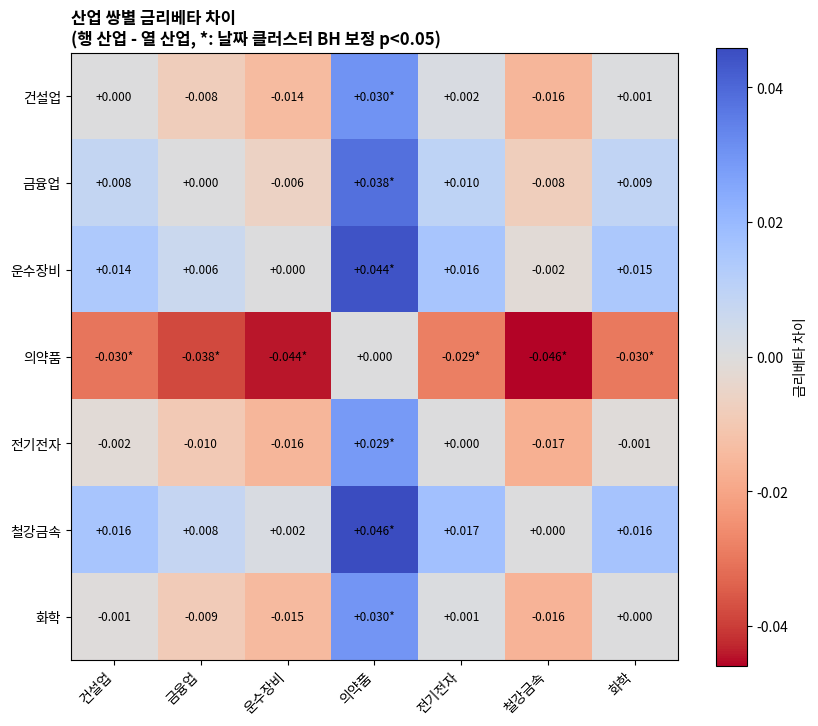

In [10]:
# 산업 쌍별 베타 차이 Heatmap
n_industries = len(industries)
difference_matrix = pd.DataFrame(
    np.zeros((n_industries, n_industries)),
    index=industries,
    columns=industries,
)

significance_matrix = pd.DataFrame(
    False,
    index=industries,
    columns=industries,
)

for _, row in pairwise_table.iterrows():
    a = row["industry_a"]
    b = row["industry_b"]
    diff = row["beta_difference_a_minus_b"]
    sig = row["significant_bh_5pct_cluster"]

    difference_matrix.loc[a, b] = diff
    difference_matrix.loc[b, a] = -diff
    significance_matrix.loc[a, b] = sig
    significance_matrix.loc[b, a] = sig

fig, ax = plt.subplots(figsize=(8.5, 7.2))

max_abs = np.abs(difference_matrix.values).max()
image = ax.imshow(
    difference_matrix.values,
    vmin=-max_abs,
    vmax=max_abs,
    cmap="coolwarm_r",
)

ax.set_xticks(np.arange(n_industries))
ax.set_yticks(np.arange(n_industries))
ax.set_xticklabels(industries, rotation=45, ha="right")
ax.set_yticklabels(industries)

for i in range(n_industries):
    for j in range(n_industries):
        value = difference_matrix.iloc[i, j]
        star = "*" if significance_matrix.iloc[i, j] else ""
        ax.text(
            j,
            i,
            f"{value:+.3f}{star}",
            ha="center",
            va="center",
            fontsize=8.5,
        )

ax.set_title(
    "산업 쌍별 금리베타 차이\n(행 산업 - 열 산업, *: 날짜 클러스터 BH 보정 p<0.05)",
    loc="left",
    fontweight="bold",
)
fig.colorbar(image, ax=ax, label="금리베타 차이")
fig.tight_layout()

fig.savefig(FIG_DIR / "05_pairwise_beta_difference_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

### 관찰 결과

- 셀 값은 행 산업 베타 - 열 산업 베타, 별표(*)는 BH 보정 후 5% 수준에서 유의한 쌍.
- 절댓값이 가장 큰 쌍은 의약품-철강금속(차이 <span style="color:#c0392b">**−0.0459**</span>)이며, **의약품이 관여한 쌍에서 색이 진하게 나타난다**.

## 구현 검증

아래 셀에서 STEP5 산출물이 설계 계약을 만족하는지 assert로 자동 검증한다.
통합회귀가 STEP4 개별회귀 베타를 재현하는지(최대 절대차이 < 1e-8)가 핵심 항목이며, 실패하면 즉시 중단된다.

In [11]:
# 구현 검증: STEP5 산출물이 설계 계약을 만족하는지 assert로 자동 검증 (실패 시 즉시 중단)
EXPECTED_INDUSTRIES = {"건설업", "금융업", "화학", "전기전자", "철강금속", "의약품", "운수장비"}

# (1) 통합회귀 베타가 STEP4 개별회귀 베타를 재현 (핵심 재현성 검증)
assert set(beta_validation["industry"]) == EXPECTED_INDUSTRIES
max_abs_diff = beta_validation["difference"].abs().max()
assert max_abs_diff < 1e-8, f"STEP4-STEP5 베타 불일치: {max_abs_diff}"

# (2) pooled_beta_table 구조·자료형·결측·범위·CI·t=beta/se
num_cols = ["beta_rate_pooled", "std_error_pooled", "t_value_pooled",
            "p_value_pooled", "ci_lower_pooled", "ci_upper_pooled"]
assert len(pooled_beta_table) == 7 and set(pooled_beta_table["industry"]) == EXPECTED_INDUSTRIES
assert not pooled_beta_table[num_cols].isna().any().any()
assert np.isfinite(pooled_beta_table[num_cols].to_numpy()).all()
assert (pooled_beta_table["std_error_pooled"] > 0).all()
assert pooled_beta_table["p_value_pooled"].between(0, 1).all()
assert (pooled_beta_table["ci_lower_pooled"] < pooled_beta_table["ci_upper_pooled"]).all()
assert ((pooled_beta_table["ci_lower_pooled"] <= pooled_beta_table["beta_rate_pooled"]) &
        (pooled_beta_table["beta_rate_pooled"] <= pooled_beta_table["ci_upper_pooled"])).all()
assert np.allclose(pooled_beta_table["t_value_pooled"],
                    pooled_beta_table["beta_rate_pooled"] / pooled_beta_table["std_error_pooled"], rtol=1e-6)

# (3) 공동검정 범위
assert 0 <= joint_pvalue <= 1 and joint_stat > 0

# (4) 쌍별: 21개 조합, BH 방향, 유의 플래그 일관성, t=diff/se
assert len(pairwise_table) == 21
assert (pairwise_table["p_value_bh"] >= pairwise_table["p_value"] - 1e-9).all()
assert (pairwise_table["significant_bh_5pct"] == (pairwise_table["p_value_bh"] < 0.05)).all()
assert np.allclose(pairwise_table["t_value"],
                    pairwise_table["beta_difference_a_minus_b"] / pairwise_table["std_error"], rtol=1e-6)

# (5) 재현성: 통합회귀 베타 == STEP4 beta_table (산업 정렬 후)
_m = beta_table[["industry", "beta_rate"]].merge(
    pooled_beta_table[["industry", "beta_rate_pooled"]], on="industry")
assert np.allclose(_m["beta_rate"], _m["beta_rate_pooled"], atol=1e-8)

# (6) 날짜 클러스터 표준오차 검증
assert np.allclose(h1_model.params.values, h1_model_cluster.params.values), "점추정 불일치"
assert "p_value_cluster" in pooled_beta_table.columns, "계수표에 클러스터 열 없음"
assert "p_value_bh_cluster" in pairwise_table.columns, "쌍별표에 클러스터 BH 열 없음"
assert pairwise_table["p_value_cluster"].between(0, 1).all(), "클러스터 p값 범위 이상"

# (7) 공동검정 클러스터 열 검증
assert "p_value_cluster" in joint_result.columns, "공동검정표에 클러스터 열 없음"
assert 0 <= joint_pvalue_cluster <= 1, "클러스터 공동검정 p값 범위 이상"
assert (joint_pvalue < 0.05) == (joint_pvalue_cluster < 0.05), "두 방식의 공동검정 판정이 다름"

print(f"모든 구현 검증 통과 — 7개 산업, STEP4-STEP5 베타 최대 절대차이 {max_abs_diff:.2e}")

모든 구현 검증 통과 — 7개 산업, STEP4-STEP5 베타 최대 절대차이 9.54e-16


### 검증 결과 및 해석

**검증한 항목**

- 재현성: 통합회귀에서 복원한 산업별 금리베타가 STEP4 개별회귀 베타와 최대 절대차이 < 1e-8로 **일치**.
- 구조: 7개 산업·행 수, 필수 컬럼, 결측·Inf 없음.
- 값·통계 일관성: p_value_pooled ∈ [0,1], std_error_pooled > 0, 신뢰구간(하한 < 상한·beta 포함), t = beta/SE.
- 공동검정 범위: 0 ≤ p-value ≤ 1, 통계량 > 0.
- 쌍별 비교: 21개 조합 존재, BH 보정 p ≥ 원 p, 유의 플래그와 BH p<0.05 일치, t = diff/SE.
- 날짜 클러스터 표준오차: HAC 모형과 클러스터 모형의 점추정이 동일(allclose), 계수표·쌍별표에 클러스터 p값 열 존재, 클러스터 p값이 [0,1] 범위 내에 있음을 확인.

**해석**

- 통합회귀가 STEP4 베타를 재현(최대 절대차이 ~1e-14 수준)하므로, **이후 공동검정·쌍별 비교가 STEP4와 동일한 베타를 기반으로 수행되었음이 보장된다**.
- 날짜 클러스터 표준오차를 추가해도 점추정은 그대로이고 SE·p값만 변하며, 실제로 7개 산업의 유의성 판정과 BH 유의 쌍 **6개**가 HAC 기준과 동일하게 유지된다.
- assert 통과는 위 모든 항목이 성립함을 뜻하며, 하나라도 위배되면 즉시 `AssertionError`로 **중단된다**.

## Baseline 결론 문장 자동 생성

공동검정과 쌍별 비교 결과를 이용해 보고서 초안 문장을 자동으로 생성한다.

In [12]:
# Baseline 결론 문장 자동 생성 (날짜 클러스터 표준오차 기준, HAC는 비교용으로 병기)
significant_pairs_cluster = pairwise_table[
    pairwise_table["significant_bh_5pct_cluster"]
].copy()

significant_pairs_hac = pairwise_table[
    pairwise_table["significant_bh_5pct"]
].copy()

if joint_pvalue_cluster < 0.05:
    conclusion = (
        f"산업별 금리베타 동일성에 대한 공동검정 결과(날짜 클러스터 표준오차 기준), "
        f"통계량은 {joint_stat_cluster:.3f}, p-value는 {joint_pvalue_cluster:.4g}로 나타났다. "
        f"이에 따라 모든 산업의 금리베타가 동일하다는 귀무가설을 "
        f"5% 유의수준에서 기각하였다. 이는 KOSPI 수익률을 통제한 조건에서도 "
        f"금리변화에 대한 산업별 수익률 반응이 동일하지 않음을 의미한다."
    )
else:
    conclusion = (
        f"산업별 금리베타 동일성에 대한 공동검정 결과(날짜 클러스터 표준오차 기준), "
        f"통계량은 {joint_stat_cluster:.3f}, p-value는 {joint_pvalue_cluster:.4g}로 나타났다. "
        f"모든 산업의 금리베타가 동일하다는 귀무가설을 "
        f"5% 유의수준에서 기각하지 못하였다. 따라서 현재 표본만으로는 "
        f"산업별 금리민감도가 통계적으로 다르다고 판단하기 어렵다."
    )

print("[Baseline 공동검정 결론]")
print(conclusion)
print(
    f"(비교: HAC 표준오차 기준 F={joint_stat:.4f}, p={joint_pvalue:.4g} — "
    f"두 방식의 5% 유의수준 판정 일치)"
)


def _pair_summary_lines(pairs, bh_col):
    lines = []
    for _, row in pairs.iterrows():
        direction = (
            "더 크다"
            if row["beta_difference_a_minus_b"] > 0
            else "더 작다"
        )
        lines.append(
            f"- {row['industry_a']}의 금리베타는 "
            f"{row['industry_b']}보다 {direction} "
            f"(차이={row['beta_difference_a_minus_b']:+.5f}, "
            f"BH p={row[bh_col]:.4g})"
        )
    return lines


print("\n[쌍별 비교 요약 — 날짜 클러스터 표준오차 기준]")
if significant_pairs_cluster.empty:
    print("BH 보정 후 5% 수준에서 유의한 산업 쌍은 확인되지 않았습니다.")
else:
    for line in _pair_summary_lines(significant_pairs_cluster, "p_value_bh_cluster"):
        print(line)

print("\n[쌍별 비교 요약 — HAC 기준, 비교용]")
if significant_pairs_hac.empty:
    print("BH 보정 후 5% 수준에서 유의한 산업 쌍은 확인되지 않았습니다.")
else:
    for line in _pair_summary_lines(significant_pairs_hac, "p_value_bh"):
        print(line)


[Baseline 공동검정 결론]
산업별 금리베타 동일성에 대한 공동검정 결과(날짜 클러스터 표준오차 기준), 통계량은 4.189, p-value는 0.0003375로 나타났다. 이에 따라 모든 산업의 금리베타가 동일하다는 귀무가설을 5% 유의수준에서 기각하였다. 이는 KOSPI 수익률을 통제한 조건에서도 금리변화에 대한 산업별 수익률 반응이 동일하지 않음을 의미한다.
(비교: HAC 표준오차 기준 F=4.2694, p=0.0002642 — 두 방식의 5% 유의수준 판정 일치)

[쌍별 비교 요약 — 날짜 클러스터 표준오차 기준]
- 운수장비의 금리베타는 의약품보다 더 크다 (차이=+0.04430, BH p=0.0002499)
- 금융업의 금리베타는 의약품보다 더 크다 (차이=+0.03830, BH p=0.0002499)
- 의약품의 금리베타는 철강금속보다 더 작다 (차이=-0.04590, BH p=0.0004502)
- 의약품의 금리베타는 화학보다 더 작다 (차이=-0.02962, BH p=0.007449)
- 의약품의 금리베타는 전기전자보다 더 작다 (차이=-0.02865, BH p=0.008922)
- 건설업의 금리베타는 의약품보다 더 크다 (차이=+0.03027, BH p=0.01798)

[쌍별 비교 요약 — HAC 기준, 비교용]
- 운수장비의 금리베타는 의약품보다 더 크다 (차이=+0.04430, BH p=0.0001772)
- 금융업의 금리베타는 의약품보다 더 크다 (차이=+0.03830, BH p=0.0001772)
- 의약품의 금리베타는 철강금속보다 더 작다 (차이=-0.04590, BH p=0.0002989)
- 의약품의 금리베타는 화학보다 더 작다 (차이=-0.02962, BH p=0.006204)
- 의약품의 금리베타는 전기전자보다 더 작다 (차이=-0.02865, BH p=0.007896)
- 건설업의 금리베타는 의약품보다 더 크다 (차이=+0.03027, BH p=0.01571)


## 해석

- 시장수익률(KOSPI)을 통제한 뒤에도 **산업별 금리베타는 공동검정 기준으로 통계적으로 다르다**.
- 쌍별 비교로 구체적으로 어느 산업쌍에서 금리베타 차이가 유의한지 확인할 수 있다.
- 이는 금리변화와 산업수익률 사이의 조건부 관련성을 나타낼 뿐이며, **인과효과를 의미하지 않는다**.

## STEP5 요약

### Takeaway

- 통합 회귀로 산업별 금리베타를 STEP4와 사실상 동일하게 복원하였다(최대 절대 차이 <1e-8 수준으로 확인).
- 공동검정 결과 p-value가 0.05 미만으로, 7개 산업 금리베타가 모두 같다는 귀무가설을 기각하였다.
- BH 보정 후에도 21개 산업쌍 중 일부가 5% 수준에서 유의하게 남는다.
- 산출물은 `results/Baseline_industry_beta/tables`, `results/Baseline_industry_beta/figures`에 저장하였다.
- 상세: `results/Baseline_industry_beta/summary.md`